# 01 · Carga, diagnóstico y preparación de conteos
**Datocracia — datos agregados CCPC 2009–2024**

1. Leer y registrar archivos originales sin ejecutar modelos.
2. Conservar estado, distrito original, municipio, sección, sexo y grupos de edad.
3. Validar **antes de agregar**: años, categorías, finitud, conteos no negativos y `LN = SV + NV + NS`.
4. Mostrar cobertura, distribuciones, casos no observables y descartes por estado.
5. Guardar los conteos y sus referencias originales para el notebook 02.

`LN` → `lista_nominal`; `SV` → `participantes`; `NV` → `no_participantes`;
`NS` → `no_especificados`. Municipio, sección, marco declarado y archivo de origen
permanecen en la base limpia.

La tasa principal es `SV / (LN − NS)`: participación entre registros especificados.
También se conserva `SV / LN` como indicador alternativo de registro. No son
intercambiables. Si `LN − NS = 0`, la tasa principal queda **sin dato**, no en cero.
Los registros válidos con participación no observable se conservan para auditar cobertura.

Los marcos declarados en los diccionarios locales son DERFE 2021 para 2009–2021 y
DERFE 2023 para 2024. **Este notebook no inventa equivalencias distritales**.
El 02 requiere equivalencias territoriales para analizar los distritos de referencia.
No se sigue a las mismas personas entre elecciones. La fuente tampoco incluye
casillas especiales ni residentes en el extranjero según sus diccionarios.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import utils as U   # funciones compartidas (ver utils.py)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.3f}".format

## 1. Configuración
Guardar los CSV originales en `data/raw/`. Solo se procesan archivos de los Conteos Censales reales; si faltan, el proceso se detiene.
Se omiten FELECCION y DEL. Edades: intervalos de tres años de 18–20 a 60–62, seguidos por 63–66, 67–70, 71–74, 75–79 y 80+ (hasta 114 años). Se excluyen las edades mayores de 114 años.
Son rangos fijos; no se construyen cohortes.


In [2]:
PATRON_ARCHIVOS = "datosabiertos_deceyec_conteoscensal*.csv"
DEFINICION_TASA = "especificados"  # Denominador: LN − NS; SV/LN se conserva aparte.
VERSION_PREPROCESADO = "ccpc_edad114_especificados"
MARCO_POR_ANIO = {a: "DERFE_2021" for a in [2009, 2012, 2015, 2018, 2021]}
MARCO_POR_ANIO[2024] = "DERFE_2023"

In [3]:
print('[01] Iniciando lectura y preparación de CSV originales.', flush=True)
from collections import Counter
from pathlib import Path

CLAVES_TERRITORIALES = ["clave_entidad", "clave_municipio", "municipio", "seccion"]

def motivos_limpieza(df: pd.DataFrame) -> pd.Series:
    """Primer motivo excluyente en filas originales; NS=LN no implica error."""
    numericas = ["anio", "lista_nominal", "participantes", "no_participantes", "no_especificados"]
    finitas = np.isfinite(df[numericas].to_numpy(dtype=float)).all(axis=1)
    conteos = df[["lista_nominal", "participantes", "no_participantes", "no_especificados"]]
    balance = df["participantes"] + df["no_participantes"] + df["no_especificados"]
    edad_fuera_rango = df.get("edad_mayor_114", pd.Series(False, index=df.index)).fillna(False)
    categoricas_validas = (
        df["sexo"].isin(["Hombres", "Mujeres", "No binario"])
        & df["tipo_seccion"].isin(["Urbana", "Mixta", "Rural"])
        & df["grupo_edad"].notna()
    )
    return pd.Series(np.select([
        ~finitas,
        df["lista_nominal"].le(0).to_numpy(),
        conteos.lt(0).any(axis=1).to_numpy(),
        (df["participantes"].gt(df["lista_nominal"]) | df["no_especificados"].gt(df["lista_nominal"])).to_numpy(),
        ~np.isclose(df["lista_nominal"], balance, rtol=0, atol=0),
        ~df["anio"].isin(U.ANIOS).to_numpy(),
        edad_fuera_rango.to_numpy(dtype=bool),
        ~categoricas_validas.to_numpy(dtype=bool),
    ], ["Nulos o no finitos numéricos", "Lista nominal <= 0", "Conteos negativos",
        "Conteos superiores a LN", "LN distinto de SV + NV + NS", "Año no considerado",
        "Edad mayor a 114 años", "Edad, sexo o tipo de sección inválido"], default="Conservado"),
        index=df.index, name="motivo")


def cargar_archivos_con_diagnostico(archivos, chunksize=100_000):
    """Lee CSV por bloques y conserva municipio/sección y edad agrupada.

    Audita cada fila original antes de sumar. Separa los agregados según
    motivo de exclusión para impedir que un valor inválido quede compensado
    por otro válido. Los porcentajes principales usan SV/(LN−NS); los no calculables se cuentan.
    """
    claves = ["anio", "entidad", "distrito", "tipo_seccion", "sexo", "grupo_edad"]
    claves += CLAVES_TERRITORIALES + ["marco_geografico", "archivo_origen", "motivo"]
    partes, estados, ejemplos = [], [], []
    resumen = Counter()
    anios = Counter()
    bins_tasa = np.linspace(0, 100, 51)
    hist_tasa = np.zeros(len(bins_tasa) - 1, dtype=np.int64)
    # Incluyen todo float finito fuera de [0, 100], sin recortar extremos.
    bins_invalidos = np.array([-np.inf, -1000, -100, -10, 0, 100, 110, 200, 1000, np.inf])
    hist_invalidos = np.zeros(len(bins_invalidos) - 1, dtype=np.int64)
    requeridas = {"AELEC", "EDONOM", "DEF", "TIPOSEC", "SEXO", "EDAD", "LN", "SV",
                  "EDOCVE", "MPIOCVE", "MPIONOM", "SECCION", "NV", "NS"}
    total_archivos = len(archivos)
    for numero, archivo in enumerate(archivos, 1):
        archivo = Path(archivo)
        print(f"[01] CSV {numero}/{total_archivos}: {archivo.name}", flush=True)
        filas_archivo = 0
        # Detectar codificación con una muestra acotada; no releer todo el CSV.
        with archivo.open("rb") as stream:
            muestra = stream.read(1024 * 1024)
        try:
            muestra.decode("utf-8-sig")
            encoding = "utf-8-sig"
        except UnicodeDecodeError:
            encoding = "latin-1"
        print(f"[01] CSV {numero}/{total_archivos}: codificación {encoding} (muestra inicial)", flush=True)
        acumuladas = []
        for bloque, original in enumerate(pd.read_csv(archivo, encoding=encoding, chunksize=chunksize,
                                    low_memory=False, usecols=lambda c: c.strip() in requeridas), start=1):
            filas_archivo += len(original)
            if bloque % 10 == 0:
                print(f"[01] CSV {numero}/{total_archivos}: {bloque} bloques, {filas_archivo:,} filas leídas", flush=True)
            original.columns = original.columns.astype(str).str.strip()
            faltan = requeridas - set(original.columns)
            if faltan:
                raise ValueError(f"{archivo.name}: faltan columnas {sorted(faltan)}")
            d = pd.DataFrame({
                "anio": pd.to_numeric(original["AELEC"], errors="coerce"),
                "entidad": original["EDONOM"].astype("string").str.strip(),
                "distrito": pd.to_numeric(original["DEF"], errors="coerce"),
                "tipo_seccion": original["TIPOSEC"].astype("string").str.strip().str.upper().map(
                    {"U": "Urbana", "M": "Mixta", "R": "Rural"}),
                "sexo": pd.to_numeric(original["SEXO"], errors="coerce").map(
                    {0: "Hombres", 1: "Mujeres", 2: "No binario"}),
                "lista_nominal": pd.to_numeric(original["LN"], errors="coerce"),
                "participantes": pd.to_numeric(original["SV"], errors="coerce"),
                "no_participantes": pd.to_numeric(original["NV"], errors="coerce"),
                "no_especificados": pd.to_numeric(original["NS"], errors="coerce"),
                "clave_entidad": pd.to_numeric(original["EDOCVE"], errors="coerce"),
                "clave_municipio": pd.to_numeric(original["MPIOCVE"], errors="coerce"),
                "municipio": original["MPIONOM"].astype("string").str.strip(),
                "seccion": pd.to_numeric(original["SECCION"], errors="coerce"),
            })
            d["marco_geografico"] = d["anio"].map(MARCO_POR_ANIO).fillna("Sin referencia")
            d["archivo_origen"] = archivo.name
            d["denominador_participacion"] = d["lista_nominal"] - d["no_especificados"]
            nombres = d["entidad"].dropna().unique()
            d["entidad"] = d["entidad"].map({x: U.normalizar_entidad(x) for x in nombres}).fillna("Sin entidad")
            edad = pd.to_numeric(original["EDAD"], errors="coerce")
            edad = edad.where(np.isfinite(edad) & edad.eq(np.floor(edad)))
            # Intervalos trienales hasta 60–62; después, cortes definidos hasta 114.
            inf = (18 + ((edad - 18) // 3) * 3).astype("Int64")
            d["grupo_edad"] = inf.astype("string") + "-" + (inf + 2).astype("string")
            for minimo, maximo, etiqueta in [(63, 66, "63-66"), (67, 70, "67-70"),
                                              (71, 74, "71-74"), (75, 79, "75-79")]:
                d.loc[edad.between(minimo, maximo), "grupo_edad"] = etiqueta
            d.loc[edad.between(80, 114), "grupo_edad"] = "80+"
            d["edad_mayor_114"] = edad.gt(114).fillna(False)
            d.loc[edad.isna() | (edad < 18) | (edad > 114), "grupo_edad"] = pd.NA
            d["motivo"] = motivos_limpieza(d)
            d["registros_originales"] = 1
            resumen["filas_originales"] += len(d)
            for valor, cuenta in original["AELEC"].astype("string").fillna("Sin año").value_counts().items():
                anios[str(valor)] += int(cuenta)
            estados.append(d.groupby(["entidad", "motivo"], dropna=False, observed=True)
                           .size().rename("registros").reset_index())
            with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
                tasa = d["participantes"].to_numpy(dtype=float) / d["denominador_participacion"].where(d["denominador_participacion"] > 0).to_numpy(dtype=float) * 100
            finita = np.isfinite(tasa)
            normales = finita & (tasa >= 0) & (tasa <= 100)
            invalidas = finita & ~normales
            hist_tasa += np.histogram(tasa[normales], bins=bins_tasa)[0]
            hist_invalidos += np.histogram(tasa[invalidas], bins=bins_invalidos)[0]
            for etiqueta, mascara in {
                "Participación < 0 %": finita & (tasa < 0),
                "Participación entre 0 y 100 %": normales,
                "Participación > 100 %": finita & (tasa > 100),
                "Participación no calculable/no finita": ~finita,
                "Votos negativos": d["participantes"].lt(0).to_numpy(),
                "Lista nominal <= 0": d["lista_nominal"].le(0).to_numpy(),
                "Año fuera de las elecciones consideradas": ~d["anio"].isin(U.ANIOS).to_numpy(),
                "Sin sección": d["seccion"].isna().to_numpy(),
                "Sin municipio": d["clave_municipio"].isna().to_numpy(),
                "Sin distrito": d["distrito"].isna().to_numpy(),
                "Sin participación observable (LN = NS)": d["denominador_participacion"].eq(0).to_numpy(),
            }.items():
                resumen[etiqueta] += int(mascara.sum())
            if sum(len(x) for x in ejemplos) < 30:
                muestra = d.loc[d.motivo.ne("Conservado")].head(30 - sum(len(x) for x in ejemplos)).copy()
                muestra["archivo_origen"] = archivo.name
                ejemplos.append(muestra)
            acumuladas.append(d.groupby(claves, dropna=False, observed=True, as_index=False)[
                ["lista_nominal", "participantes", "no_participantes", "no_especificados", "denominador_participacion", "registros_originales"]].sum(min_count=1))
        agregado = pd.concat(acumuladas, ignore_index=True).groupby(
            claves, dropna=False, observed=True, as_index=False)[
            ["lista_nominal", "participantes", "no_participantes", "no_especificados", "denominador_participacion", "registros_originales"]].sum(min_count=1)
        for col in agregado.select_dtypes(include=["object", "string"]).columns:
            agregado[col] = agregado[col].astype("category")
        partes.append(agregado)
        print(f"[01] Completados {numero}/{total_archivos} CSV ({numero/total_archivos:.1%}); "
              f"{filas_archivo:,} filas en este archivo", flush=True)
        del acumuladas, agregado, original, d
    # Categorías compartidas: la concatenación no vuelve a expandir el texto.
    for col in partes[0].select_dtypes(include="category").columns:
        categorias = sorted(set().union(*(set(p[col].cat.categories) for p in partes)))
        for p in partes:
            p[col] = p[col].cat.set_categories(categorias)
    crudo = pd.concat(partes, ignore_index=True)
    partes.clear()
    # Cada archivo ya se agrupó y archivo_origen forma parte de la clave:
    # una segunda agrupación global no combinaría filas adicionales.
    por_estado = pd.concat(estados, ignore_index=True).groupby(
        ["entidad", "motivo"], dropna=False, as_index=False)["registros"].sum()
    auditoria = {"resumen": dict(resumen), "por_estado_motivo": por_estado,
                 "anios": pd.Series(dict(anios), name="registros"),
                 "bins_tasa": bins_tasa, "hist_tasa": hist_tasa,
                 "bins_invalidos": bins_invalidos, "hist_invalidos": hist_invalidos,
                 "ejemplos": pd.concat(ejemplos, ignore_index=True) if ejemplos else pd.DataFrame()}
    return crudo, auditoria


def cobertura_elecciones(crudo: pd.DataFrame, claves: list) -> pd.DataFrame:
    """0/6..6/6 sobre el universo de unidades presentes en los archivos.

    Una elección válida exige al menos una fila original conservada. Una
    unidad totalmente ausente de todos los archivos no se puede contar.
    La geografía no se homologa con este diagnóstico.
    """
    t = crudo[claves + ["anio", "motivo", "denominador_participacion"]].copy()
    t["anio_valido"] = t["anio"].where(t["anio"].isin(U.ANIOS) & t["motivo"].eq("Conservado") & t["denominador_participacion"].gt(0))
    n = t.groupby(claves, dropna=False, observed=True)["anio_valido"].nunique()
    cuentas = n.value_counts().reindex(range(len(U.ANIOS) + 1), fill_value=0).sort_index()
    return pd.DataFrame({"elecciones_validas": [f"{x}/{len(U.ANIOS)}" for x in cuentas.index],
                         "unidades": cuentas.to_numpy(),
                         "porcentaje_unidades": cuentas.to_numpy() / max(len(n), 1) * 100})


archivos = sorted(U.DIR_RAW.glob(PATRON_ARCHIVOS))
if not archivos:
    raise FileNotFoundError(f"No se encontraron archivos reales en {U.DIR_RAW} con patrón {PATRON_ARCHIVOS}")
# Auditar registros originales antes de cualquier agregación.
crudo, auditoria = cargar_archivos_con_diagnostico(archivos)
FUENTE = "REAL"
print("Fuente:", FUENTE)
print(f"Filas originales: {auditoria['resumen']['filas_originales']:,}")
print(f"Filas agregadas por sección, grupo de edad y motivo: {len(crudo):,}")
display(crudo.head())

[01] Iniciando lectura y preparación de CSV originales.
[01] CSV 1/192: datosabiertos_deceyec_conteoscensales2009_ags.csv
[01] CSV 1/192: codificación utf-8-sig (muestra inicial)
[01] Completados 1/192 CSV (0.5%); 77,391 filas en este archivo
[01] CSV 2/192: datosabiertos_deceyec_conteoscensales2009_bc.csv
[01] CSV 2/192: codificación utf-8-sig (muestra inicial)
[01] Completados 2/192 CSV (1.0%); 201,728 filas en este archivo
[01] CSV 3/192: datosabiertos_deceyec_conteoscensales2009_bcs.csv
[01] CSV 3/192: codificación utf-8-sig (muestra inicial)
[01] Completados 3/192 CSV (1.6%); 48,740 filas en este archivo
[01] CSV 4/192: datosabiertos_deceyec_conteoscensales2009_camp.csv
[01] CSV 4/192: codificación utf-8-sig (muestra inicial)
[01] Completados 4/192 CSV (2.1%); 64,436 filas en este archivo
[01] CSV 5/192: datosabiertos_deceyec_conteoscensales2009_cdmx.csv
[01] CSV 5/192: codificación utf-8-sig (muestra inicial)
[01] Completados 5/192 CSV (2.6%); 801,738 filas en este archivo
[01] C

,anio,entidad,distrito,tipo_seccion,sexo,grupo_edad,clave_entidad,clave_municipio,municipio,seccion,marco_geografico,archivo_origen,motivo,lista_nominal,participantes,no_participantes,no_especificados,denominador_participacion,registros_originales
0,2009,AGUASCALIENTES,1.000,Mixta,Hombres,18-20,1,2,Asientos,338,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_ags.csv,Conservado,64,19,45,0,64,3
1,2009,AGUASCALIENTES,1.000,Mixta,Hombres,18-20,1,2,Asientos,339,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_ags.csv,Conservado,47,13,34,0,47,3
2,2009,AGUASCALIENTES,1.000,Mixta,Hombres,18-20,1,2,Asientos,343,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_ags.csv,Conservado,85,33,52,0,85,3
3,2009,AGUASCALIENTES,1.000,Mixta,Hombres,18-20,1,2,Asientos,349,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_ags.csv,Conservado,52,15,37,0,52,3
4,2009,AGUASCALIENTES,1.000,Mixta,Hombres,18-20,1,3,Calvillo,355,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_ags.csv,Conservado,46,19,27,0,46,3


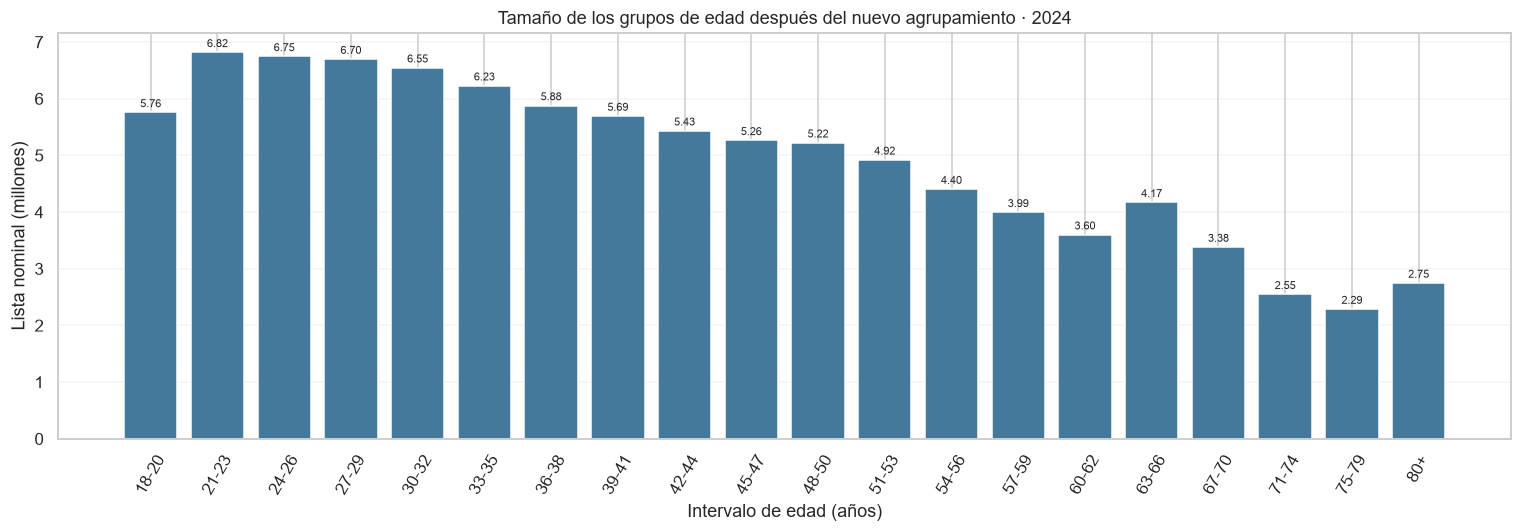

Lista nominal 2024 por grupo (edades 18–114):


,lista_nominal_2024
grupo_edad,
18-20,5756765
21-23,6816376
24-26,6745049
27-29,6697542
30-32,6545834
33-35,6228610
36-38,5878173
39-41,5692855
42-44,5432973


In [4]:
# Histograma de tamaños inmediatamente después de definir y agregar los grupos de edad.
# Se muestra una sola elección (2024) para no sumar varias veces la lista nominal.
grupos_edad_objetivo = [f"{inicio}-{inicio+2}" for inicio in range(18, 63, 3)] + [
    "63-66", "67-70", "71-74", "75-79", "80+"]
tamanos_grupo_2024 = (
    crudo.loc[crudo["anio"].eq(2024) & crudo["motivo"].eq("Conservado")]
    .groupby("grupo_edad", observed=True)["lista_nominal"].sum()
    .reindex(grupos_edad_objetivo, fill_value=0)
)
fig, ax = plt.subplots(figsize=(14, 5))
barras = ax.bar(tamanos_grupo_2024.index, tamanos_grupo_2024.to_numpy() / 1_000_000,
                color="#45799C", edgecolor="white")
ax.set(title="Tamaño de los grupos de edad después del nuevo agrupamiento · 2024",
       xlabel="Intervalo de edad (años)", ylabel="Lista nominal (millones)")
ax.tick_params(axis="x", labelrotation=60)
ax.grid(axis="y", alpha=.22)
ax.set_axisbelow(True)
ax.bar_label(barras, fmt="%.2f", fontsize=7, padding=2)
plt.tight_layout()
plt.show()
print("Lista nominal 2024 por grupo (edades 18–114):")
display(tamanos_grupo_2024.rename("lista_nominal_2024").to_frame())


## 2. Diagnóstico antes de limpiar

Los conteos de errores y descartes se calculan sobre **filas originales**, antes de
agregar edades o secciones: un valor negativo no puede quedar oculto al sumarlo.
Los porcentajes de participación usan `100 × SV / (LN − NS)`. Los porcentajes inválidos,
los valores no calculables y los votos negativos se muestran explícitamente.

La cobertura `0/6`…`6/6` cuenta **unidades distintas**, no filas repetidas por año.
Una elección es válida si tiene al menos una fila que supera la limpieza y tiene `LN − NS > 0`.
Se muestran por separado sección × sexo × edad y segmento estatal × sexo × edad.
`0/6` incluye solo unidades presentes en los archivos con cero elecciones válidas;
no permite contar unidades ausentes de todos los archivos. Las claves geográficas
faltantes se mantienen en el diagnóstico; el notebook 02 puede excluirlas al pivotear.
**Este conteo no homologa territorios ni garantiza que las observaciones sean comparables.**

[01] Calculando cobertura y diagnosticos de calidad.


,elecciones_validas,unidades,porcentaje_unidades
0,6/6,1280,91.625
1,5/6,0,0.000
2,4/6,0,0.000
3,3/6,0,0.000
4,2/6,0,0.000
5,1/6,54,3.865
6,0/6,63,4.510


,elecciones_validas,unidades,porcentaje_unidades
0,6/6,2162693,74.192
1,5/6,382564,13.124
2,4/6,139958,4.801
3,3/6,35868,1.230
4,2/6,61550,2.111
5,1/6,127122,4.361
6,0/6,5259,0.180


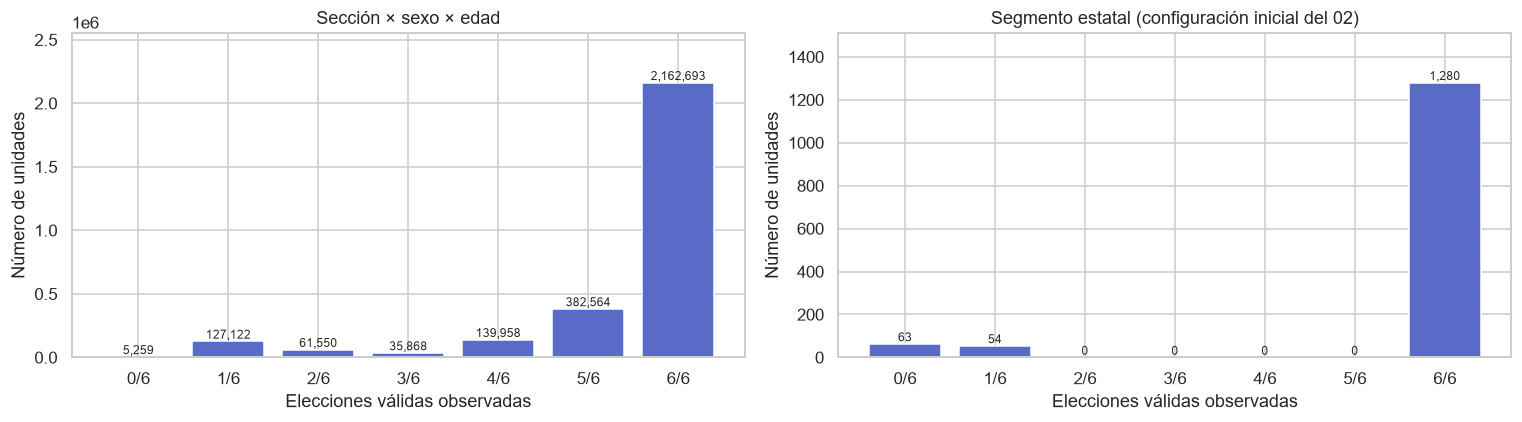

In [5]:
print('[01] Calculando cobertura y diagnosticos de calidad.', flush=True)
claves_segmento = ["entidad", "sexo", "grupo_edad"]
claves_seccion = ["clave_entidad", "clave_municipio", "seccion", "sexo", "grupo_edad"]
cobertura_segmentos = cobertura_elecciones(crudo, claves_segmento)
display(cobertura_segmentos.sort_index(ascending=False).reset_index(drop=True))
if FUENTE == "REAL":
    cobertura_secciones = cobertura_elecciones(crudo, claves_seccion)
    display(cobertura_secciones.sort_index(ascending=False).reset_index(drop=True))
    coberturas = [("Sección × sexo × edad", cobertura_secciones),
                  ("Segmento estatal (configuración inicial del 02)", cobertura_segmentos)]
else:
    coberturas = [("Segmento simulado", cobertura_segmentos)]
fig, axes = plt.subplots(1, len(coberturas), figsize=(7 * len(coberturas), 4), squeeze=False)
for ax, (titulo, tabla) in zip(axes.ravel(), coberturas):
    barras = ax.bar(tabla["elecciones_validas"], tabla["unidades"], color="#596ac7")
    ax.bar_label(barras, labels=[f"{v:,}" for v in tabla["unidades"]], fontsize=8)
    ax.set(title=titulo, xlabel="Elecciones válidas observadas", ylabel="Número de unidades")
    ax.margins(y=.18)
plt.tight_layout(); plt.show()

,registros_originales,porcentaje_del_total
filas_originales,54872712,100.000
Participación < 0 %,0,0.000
Participación entre 0 y 100 %,53476980,97.456
Participación > 100 %,0,0.000
Participación no calculable/no finita,1395732,2.544
Votos negativos,0,0.000
Lista nominal <= 0,0,0.000
Año fuera de las elecciones consideradas,0,0.000
Sin sección,0,0.000
Sin municipio,0,0.000


Los indicadores de calidad pueden solaparse; los motivos de eliminación posteriores son excluyentes.


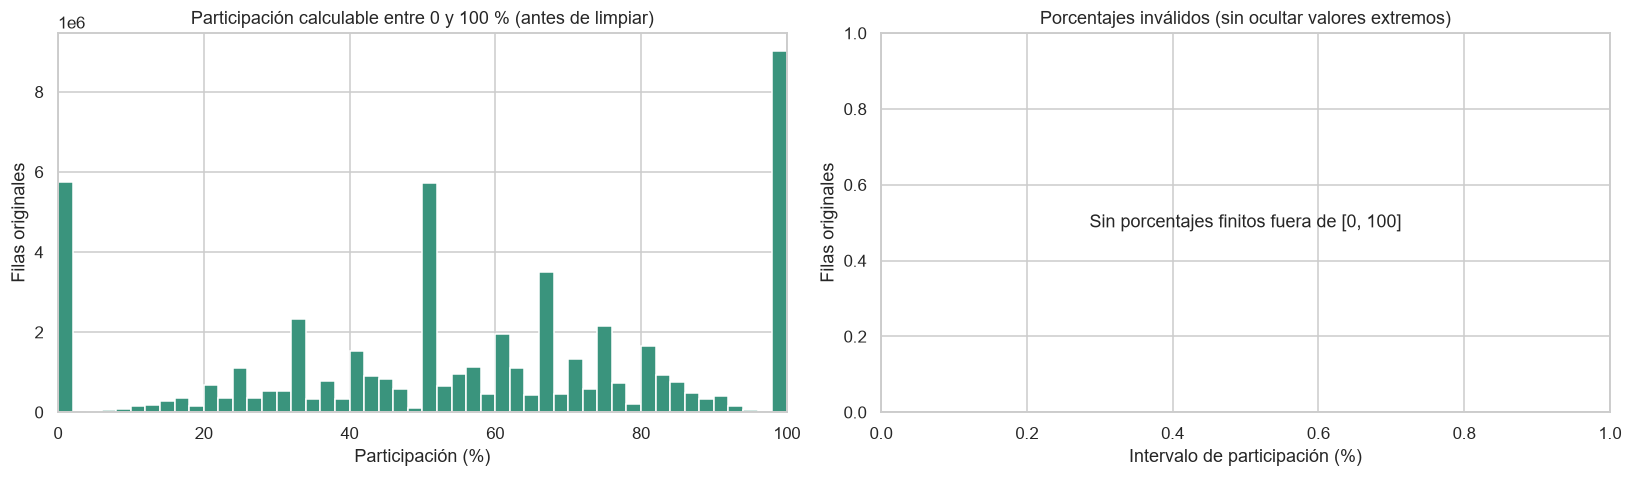

Ejemplos de filas excluibles, con municipio, sección y archivo de origen:


,anio,entidad,distrito,tipo_seccion,sexo,lista_nominal,participantes,no_participantes,no_especificados,clave_entidad,clave_municipio,municipio,seccion,marco_geografico,archivo_origen,denominador_participacion,grupo_edad,edad_mayor_114,motivo,registros_originales
0,2009,AGUASCALIENTES,1.000,Mixta,Hombres,1,0,1,0,1,3,Calvillo,380,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_ags.csv,1,<NA>,True,Edad mayor a 114 años,1
1,2009,AGUASCALIENTES,1.000,Urbana,Hombres,1,0,1,0,1,6,Pabellón de Arteaga,420,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_ags.csv,1,<NA>,True,Edad mayor a 114 años,1
2,2009,AGUASCALIENTES,1.000,Rural,Hombres,1,1,0,0,1,6,Pabellón de Arteaga,426,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_ags.csv,1,<NA>,True,Edad mayor a 114 años,1
3,2009,BAJA CALIFORNIA,3.000,Urbana,Mujeres,1,0,1,0,2,1,Ensenada,46,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_bc.csv,1,<NA>,True,Edad mayor a 114 años,1
4,2009,BAJA CALIFORNIA,2.000,Urbana,Mujeres,1,0,1,0,2,2,Mexicali,267,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_bc.csv,1,<NA>,True,Edad mayor a 114 años,1
5,2009,BAJA CALIFORNIA,1.000,Urbana,Hombres,1,0,1,0,2,2,Mexicali,497,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_bc.csv,1,<NA>,True,Edad mayor a 114 años,1
6,2009,BAJA CALIFORNIA,NaN,Mixta,Hombres,1,0,1,0,2,2,Mexicali,568,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_bc.csv,1,<NA>,True,Edad mayor a 114 años,1
7,2009,BAJA CALIFORNIA,2.000,Urbana,Hombres,1,0,1,0,2,2,Mexicali,687,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_bc.csv,1,<NA>,True,Edad mayor a 114 años,1
8,2009,BAJA CALIFORNIA,5.000,Urbana,Mujeres,1,0,1,0,2,4,Tijuana,1142,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_bc.csv,1,<NA>,True,Edad mayor a 114 años,1
9,2009,BAJA CALIFORNIA,8.000,Urbana,Mujeres,1,0,1,0,2,4,Tijuana,1176,DERFE_2021,datosabiertos_deceyec_conteoscensales2009_bc.csv,1,<NA>,True,Edad mayor a 114 años,1


In [6]:
resumen_calidad = pd.Series(auditoria["resumen"], name="registros_originales").to_frame()
resumen_calidad["porcentaje_del_total"] = resumen_calidad["registros_originales"] / auditoria["resumen"]["filas_originales"] * 100
display(resumen_calidad)
print("Los indicadores de calidad pueden solaparse; los motivos de eliminación posteriores son excluyentes.")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
bins = auditoria["bins_tasa"]
axes[0].bar(bins[:-1], auditoria["hist_tasa"], width=np.diff(bins), align="edge", color="#3a947d")
axes[0].set(title="Participación calculable entre 0 y 100 % (antes de limpiar)",
            xlabel="Participación (%)", ylabel="Filas originales", xlim=(0, 100))
etiquetas_invalidos = ["< −1000", "−1000 a −100", "−100 a −10", "−10 a <0", "0 a 100",
                       ">100 a 110", "110 a 200", "200 a 1000", "≥1000"]
frecuencias = auditoria["hist_invalidos"]
if frecuencias.sum():
    barras = axes[1].bar(etiquetas_invalidos, frecuencias, color="#cc6655")
    axes[1].bar_label(barras, fontsize=8)
    axes[1].tick_params(axis="x", rotation=45)
else:
    axes[1].text(.5, .5, "Sin porcentajes finitos fuera de [0, 100]", ha="center", va="center", transform=axes[1].transAxes)
axes[1].set(title="Porcentajes inválidos (sin ocultar valores extremos)", xlabel="Intervalo de participación (%)", ylabel="Filas originales")
plt.tight_layout(); plt.show()
if not auditoria["ejemplos"].empty:
    print("Ejemplos de filas excluibles, con municipio, sección y archivo de origen:")
    display(auditoria["ejemplos"])

,anio_original,registros_originales,anio_numerico,eleccion_considerada
0,2009,8706843,2009,True
1,2012,8604456,2012,True
2,2015,9106059,2015,True
3,2018,9251122,2018,True
4,2021,9430502,2021,True
5,2024,9773730,2024,True


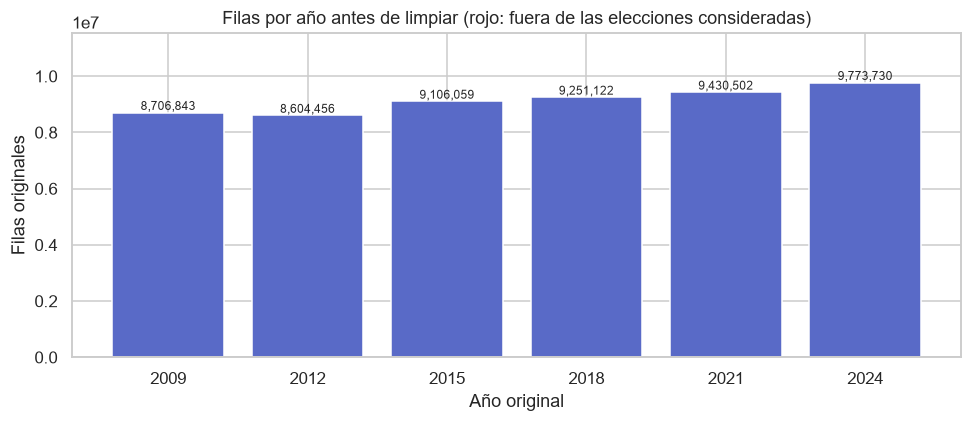

In [7]:
conteo_anios = auditoria["anios"].rename_axis("anio_original").reset_index(name="registros_originales")
conteo_anios["anio_numerico"] = pd.to_numeric(conteo_anios["anio_original"], errors="coerce")
conteo_anios["eleccion_considerada"] = conteo_anios["anio_numerico"].isin(U.ANIOS)
conteo_anios = conteo_anios.sort_values(["anio_numerico", "anio_original"], na_position="last").reset_index(drop=True)
display(conteo_anios)
fig, ax = plt.subplots(figsize=(max(9, len(conteo_anios) * .7), 4))
barras = ax.bar(conteo_anios["anio_original"], conteo_anios["registros_originales"],
                color=np.where(conteo_anios["eleccion_considerada"], "#596ac7", "#cc6655"))
ax.bar_label(barras, labels=[f"{v:,}" for v in conteo_anios["registros_originales"]], fontsize=8)
ax.set(title="Filas por año antes de limpiar (rojo: fuera de las elecciones consideradas)",
       xlabel="Año original", ylabel="Filas originales")
ax.margins(y=.18)
plt.tight_layout(); plt.show()

,registros_iniciales,registros_conservados,registros_eliminados,porcentaje_eliminado,Edad mayor a 114 años
entidad,,,,,
CHIAPAS,1724737,1724635,102,0.006,102
GUERRERO,2104967,2104879,88,0.004,88
VERACRUZ,4018791,4018627,164,0.004,164
HIDALGO,1412101,1412050,51,0.004,51
PUEBLA,2277286,2277213,73,0.003,73
TAMAULIPAS,1607151,1607106,45,0.003,45
CHIHUAHUA,2330854,2330790,64,0.003,64
OAXACA,2050122,2050067,55,0.003,55
NAYARIT,748261,748241,20,0.003,20


Porcentaje eliminado = filas originales eliminadas del estado / filas originales iniciales del estado × 100.
Cada fila se atribuye al primer motivo de exclusión: no se duplica entre motivos.
No tener distrito, municipio o sección se reporta, pero no provoca eliminación numérica en este notebook.


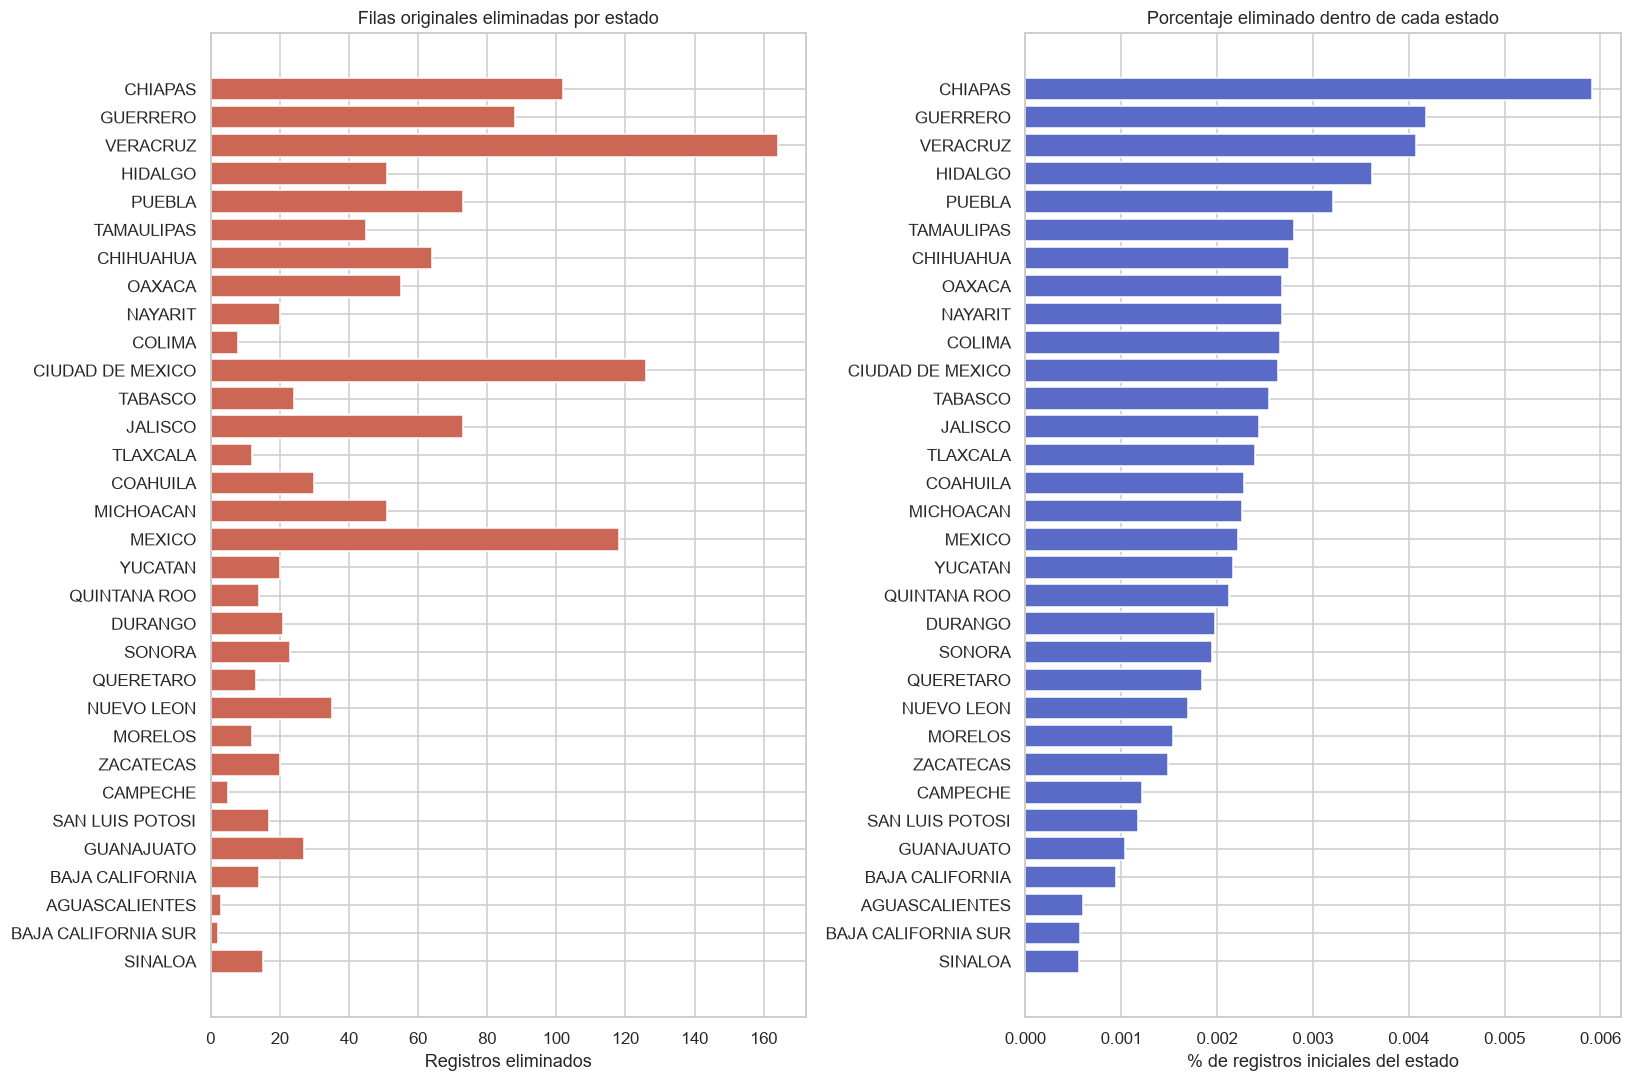

In [8]:
motivos_por_estado = auditoria["por_estado_motivo"].pivot_table(
    index="entidad", columns="motivo", values="registros", aggfunc="sum", fill_value=0)
motivos_por_estado.columns.name = None
resumen_estados = motivos_por_estado.copy()
resumen_estados["registros_iniciales"] = motivos_por_estado.sum(axis=1)
resumen_estados["registros_conservados"] = motivos_por_estado.get("Conservado", pd.Series(0, index=motivos_por_estado.index))
resumen_estados["registros_eliminados"] = resumen_estados["registros_iniciales"] - resumen_estados["registros_conservados"]
resumen_estados["porcentaje_eliminado"] = 100 * resumen_estados["registros_eliminados"] / resumen_estados["registros_iniciales"]
columnas_motivos = [c for c in motivos_por_estado.columns if c != "Conservado"]
resumen_estados = resumen_estados[["registros_iniciales", "registros_conservados", "registros_eliminados", "porcentaje_eliminado"] + columnas_motivos]
resumen_estados = resumen_estados.sort_values(["porcentaje_eliminado", "registros_eliminados"], ascending=False)
display(resumen_estados)
print("Porcentaje eliminado = filas originales eliminadas del estado / filas originales iniciales del estado × 100.")
print("Cada fila se atribuye al primer motivo de exclusión: no se duplica entre motivos.")
print("No tener distrito, municipio o sección se reporta, pero no provoca eliminación numérica en este notebook.")
fig, axes = plt.subplots(1, 2, figsize=(15, 10))
orden = resumen_estados.index[::-1]
axes[0].barh(orden, resumen_estados.loc[orden, "registros_eliminados"], color="#cc6655")
axes[0].set(title="Filas originales eliminadas por estado", xlabel="Registros eliminados")
axes[1].barh(orden, resumen_estados.loc[orden, "porcentaje_eliminado"], color="#596ac7")
axes[1].set(title="Porcentaje eliminado dentro de cada estado", xlabel="% de registros iniciales del estado")
plt.tight_layout(); plt.show()

## 3. Limpieza conservando el territorio

Se excluyen los registros por su motivo identificado **antes de la agregación**.
Las claves de entidad, municipio, nombre municipal y sección permanecen en `df`
y en `ccpc_limpio.csv.gz`. Los conteos del reporte corresponden a filas originales;
el tamaño de `df` corresponde a filas agregadas por sección y grupo de edad.

### Comprobación de los resultados de limpieza

Se contrastan los descartes globales con la suma de los estados. La conservación
de municipio y sección permite inspeccionar la ubicación antes de continuar al notebook 02.

In [9]:
# Excluir según el motivo definido ANTES de sumar; conservar NS y territorio.
df = crudo.loc[crudo["motivo"].eq("Conservado")]
filas_originales_conservadas = int(df["registros_originales"].sum())
del crudo
import gc
gc.collect()
df.drop(columns="motivo", inplace=True)
df.reset_index(drop=True, inplace=True)

df["anio"] = df["anio"].astype(int)
for c in ["clave_entidad", "clave_municipio", "seccion", "distrito"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
df["sexo"] = df["sexo"].map(U.normalizar_sexo)
df["definicion_tasa"] = DEFINICION_TASA
df["version_preprocesado"] = VERSION_PREPROCESADO
# Una tasa no observable permanece NaN. No se considera abstención.
df["tasa"] = df["participantes"] / df["denominador_participacion"].where(df["denominador_participacion"] > 0)
df["tasa_sobre_lista_nominal"] = df["participantes"] / df["lista_nominal"]
df["proporcion_no_especificada"] = df["no_especificados"] / df["lista_nominal"]
reporte = {
    "filas_originales_iniciales": auditoria["resumen"]["filas_originales"],
    "filas_originales_conservadas": filas_originales_conservadas,
    "filas_originales_eliminadas": int(resumen_estados["registros_eliminados"].sum()),
    "filas_agregadas_limpias": len(df),
    "filas_agregadas_sin_tasa_observable": int(df["tasa"].isna().sum()),
}
assert reporte["filas_originales_iniciales"] == filas_originales_conservadas + reporte["filas_originales_eliminadas"]
assert filas_originales_conservadas == int(resumen_estados["registros_conservados"].sum())
assert df["lista_nominal"].eq(df["participantes"] + df["no_participantes"] + df["no_especificados"]).all()
display(pd.Series(reporte, name="conteo").to_frame())
display(df[["anio", "entidad", "distrito", "clave_municipio", "municipio", "seccion",
            "tipo_seccion", "sexo", "grupo_edad", "lista_nominal", "participantes",
            "no_participantes", "no_especificados", "denominador_participacion", "tasa", "marco_geografico"]].head(20))

,conteo
filas_originales_iniciales,54872712
filas_originales_conservadas,54871367
filas_originales_eliminadas,1345
filas_agregadas_limpias,16184204
filas_agregadas_sin_tasa_observable,377568


,anio,entidad,distrito,clave_municipio,municipio,seccion,tipo_seccion,sexo,grupo_edad,lista_nominal,participantes,no_participantes,no_especificados,denominador_participacion,tasa,marco_geografico
0,2009,AGUASCALIENTES,1,2,Asientos,338,Mixta,Hombres,18-20,64,19,45,0,64,0.297,DERFE_2021
1,2009,AGUASCALIENTES,1,2,Asientos,339,Mixta,Hombres,18-20,47,13,34,0,47,0.277,DERFE_2021
2,2009,AGUASCALIENTES,1,2,Asientos,343,Mixta,Hombres,18-20,85,33,52,0,85,0.388,DERFE_2021
3,2009,AGUASCALIENTES,1,2,Asientos,349,Mixta,Hombres,18-20,52,15,37,0,52,0.288,DERFE_2021
4,2009,AGUASCALIENTES,1,3,Calvillo,355,Mixta,Hombres,18-20,46,19,27,0,46,0.413,DERFE_2021
5,2009,AGUASCALIENTES,1,3,Calvillo,357,Mixta,Hombres,18-20,26,10,16,0,26,0.385,DERFE_2021
6,2009,AGUASCALIENTES,1,3,Calvillo,380,Mixta,Hombres,18-20,55,23,32,0,55,0.418,DERFE_2021
7,2009,AGUASCALIENTES,1,4,Cosío,388,Mixta,Hombres,18-20,33,13,20,0,33,0.394,DERFE_2021
8,2009,AGUASCALIENTES,1,5,Jesús María,392,Mixta,Hombres,18-20,157,48,109,0,157,0.306,DERFE_2021
9,2009,AGUASCALIENTES,1,5,Jesús María,401,Mixta,Hombres,18-20,93,25,68,0,93,0.269,DERFE_2021


In [10]:
print("Años presentes :", sorted(df["anio"].unique()), "| esperados:", U.ANIOS)
for c in ["entidad", "distrito", "clave_municipio", "municipio", "seccion", "tipo_seccion", "sexo", "grupo_edad"]:
    print(f"{c:>13}: {df[c].nunique():>4} valores únicos")
print("\nGrupos de edad (ordenados):", U.orden_grupos_edad(df["grupo_edad"]))
print("Tipos de sección          :", sorted(df["tipo_seccion"].unique()))
print("Entidades sin región asignada:", sorted(set(df["entidad"]) - set(U.REGION_POR_ENTIDAD)))

# Cobertura de participación y diferencia entre denominadores por elección.
calidad_por_anio = df.groupby("anio")[["lista_nominal", "participantes", "no_participantes", "no_especificados"]].sum()
calidad_por_anio["porcentaje_no_especificado"] = 100 * calidad_por_anio.no_especificados / calidad_por_anio.lista_nominal
calidad_por_anio["participacion_especificados_pct"] = 100 * calidad_por_anio.participantes / (calidad_por_anio.lista_nominal - calidad_por_anio.no_especificados).where(lambda x: x > 0)
calidad_por_anio["participacion_sobre_ln_pct"] = 100 * calidad_por_anio.participantes / calidad_por_anio.lista_nominal
display(calidad_por_anio)

Años presentes : [np.int64(2009), np.int64(2012), np.int64(2015), np.int64(2018), np.int64(2021), np.int64(2024)] | esperados: [2009, 2012, 2015, 2018, 2021, 2024]
      entidad:   32 valores únicos
     distrito:   41 valores únicos
clave_municipio:  570 valores únicos
    municipio: 2432 valores únicos
      seccion: 6908 valores únicos
 tipo_seccion:    3 valores únicos
         sexo:    3 valores únicos
   grupo_edad:   20 valores únicos

Grupos de edad (ordenados): ['18-20', '21-23', '24-26', '27-29', '30-32', '33-35', '36-38', '39-41', '42-44', '45-47', '48-50', '51-53', '54-56', '57-59', '60-62', '63-66', '67-70', '71-74', '75-79', '80+']
Tipos de sección          : ['Mixta', 'Rural', 'Urbana']
Entidades sin región asignada: []


,lista_nominal,participantes,no_participantes,no_especificados,porcentaje_no_especificado,participacion_especificados_pct,participacion_sobre_ln_pct
anio,,,,,,,
2009,77480930,33316869,42298180,1865881,2.408,44.061,43.000
2012,76490860,47383120,28939091,168649,0.220,62.083,61.946
2015,83563398,36926604,41517824,5118970,6.126,47.074,44.190
2018,89123875,51784362,31249780,6089733,6.833,62.365,58.104
2021,93532012,46389173,43099527,4043312,4.323,51.838,49.597
2024,98330290,54899210,37105429,6325651,6.433,59.670,55.831


## 4. Exploración descriptiva
Las tasas se calculan sumando participantes y denominadores especificados, no
promediando porcentajes. Los valores siguen en proporción 0–1 en esta base.
El 02 construye los indicadores longitudinales (nivel y brecha en puntos porcentuales; tendencias en puntos porcentuales por año). El 03 ajusta seis perfiles con K-Means usando cuatro indicadores de participación; la edad y el sexo se reservan para describir los perfiles.

anio  2009  2012  2015  2018  2021  2024
tasa 0.441 0.621 0.471 0.624 0.518 0.597


C:\Users\pokem\AppData\Local\Temp\ipykernel_20116\722997786.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = d.groupby(por)[["participantes", "denominador_participacion"]].sum(min_count=1)
C:\Users\pokem\AppData\Local\Temp\ipykernel_20116\722997786.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = d.groupby(por)[["participantes", "denominador_participacion"]].sum(min_count=1)


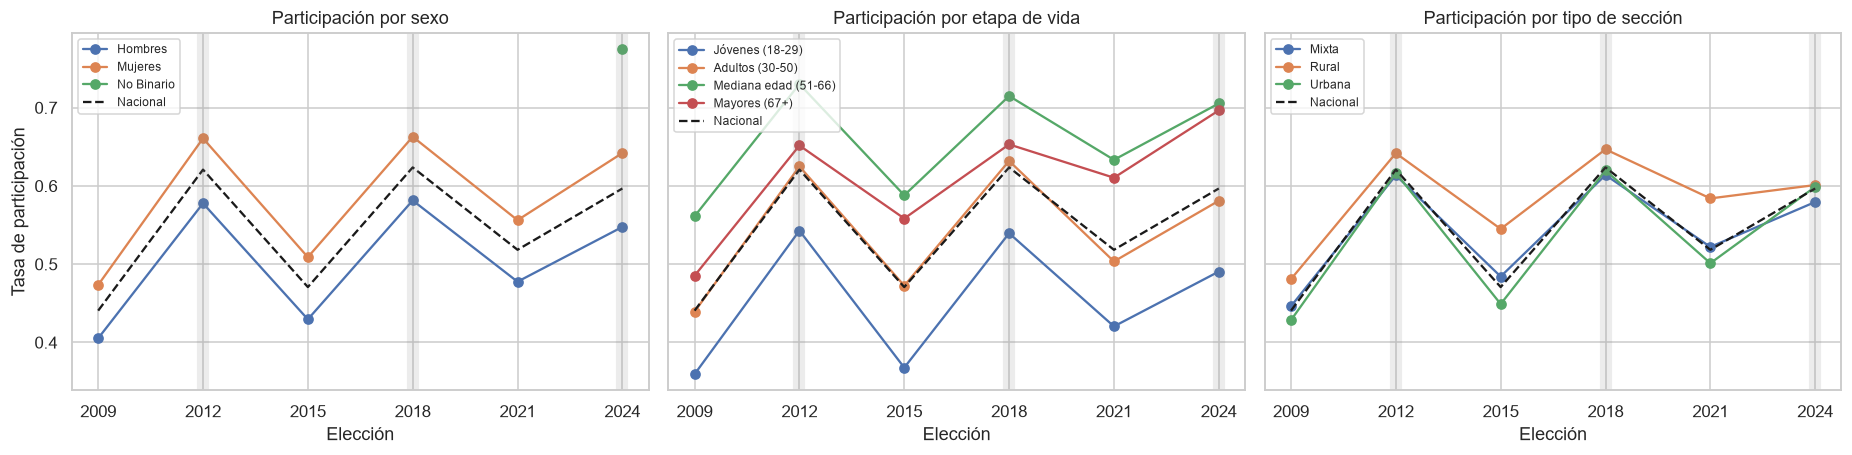

In [11]:
def tasa(d, por):
    g = d.groupby(por)[["participantes", "denominador_participacion"]].sum(min_count=1)
    return (g["participantes"] / g["denominador_participacion"].where(g["denominador_participacion"] > 0)).rename("tasa")

df["ciclo_vida"] = df["grupo_edad"].astype("string").map(U.edad_inferior).map(U.ciclo_vida)

# --- Participación nacional por elección ---
nac = tasa(df, "anio")
print(nac.round(3).to_frame().T)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), sharey=True)
for ax, (var, titulo) in zip(axes, [("sexo", "por sexo"), ("ciclo_vida", "por etapa de vida"), ("tipo_seccion", "por tipo de sección")]):
    t = tasa(df, ["anio", var]).unstack(var)
    if var == "ciclo_vida":
        t = t[[c for c in U.ORDEN_CICLO if c in t.columns]]
    t.plot(ax=ax, marker="o")
    ax.plot(nac.index, nac.values, "k--", label="Nacional")
    for a in U.ANIOS_PRES:
        ax.axvline(a, color="gray", alpha=.15, lw=8)   # franjas = elecciones presidenciales
    ax.set(title=f"Participación {titulo}", xlabel="Elección", xticks=U.ANIOS)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Tasa de participación")
plt.tight_layout(); plt.show()

C:\Users\pokem\AppData\Local\Temp\ipykernel_20116\722997786.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = d.groupby(por)[["participantes", "denominador_participacion"]].sum(min_count=1)


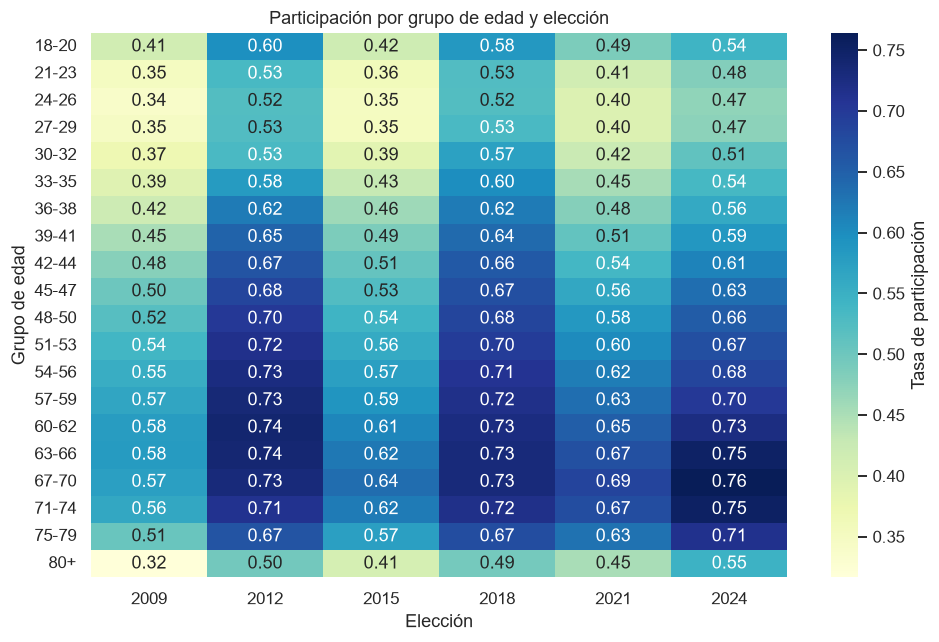

In [12]:
# Mapa de calor: tasa por grupo de edad x elección (¿se ve el efecto "presidencial vs intermedia"?)
orden = U.orden_grupos_edad(df["grupo_edad"])
m = tasa(df, ["grupo_edad", "anio"]).unstack("anio").loc[orden]
plt.figure(figsize=(9, max(6, len(orden) * .3)))
sns.heatmap(m, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "Tasa de participación"})
plt.title("Participación por grupo de edad y elección"); plt.ylabel("Grupo de edad"); plt.xlabel("Elección")
plt.tight_layout(); plt.show()

In [13]:
# Brecha de participación entre sexos (mujeres - hombres), por elección
t = tasa(df, ["anio", "sexo"]).unstack("sexo")
if {"Hombres", "Mujeres"} <= set(t.columns):
    print("Brecha Mujeres - Hombres (puntos porcentuales):")
    print(((t["Mujeres"] - t["Hombres"]) * 100).round(2).to_frame("pp").T)

C:\Users\pokem\AppData\Local\Temp\ipykernel_20116\722997786.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = d.groupby(por)[["participantes", "denominador_participacion"]].sum(min_count=1)


Brecha Mujeres - Hombres (puntos porcentuales):
anio  2009  2012  2015  2018  2021  2024
pp   6.820 8.310 7.940 8.140 7.860 9.440


## 5. Guardar la base preparada
Se conservan municipio, sección, claves originales, marco declarado, archivo fuente,
`LN`, `SV`, `NV`, `NS`, denominador, indicadores y número de filas originales.
No se aplica una equivalencia distrital supuesta. La marca de preparación permite comprobar que los notebooks posteriores usan el esquema esperado.
Después de guardar se libera la tabla grande de memoria.


In [14]:
print('[01] Guardando la base limpia comprimida por bloques.', flush=True)
ruta_salida = U.DIR_PROC / "ccpc_limpio.csv.gz"
ruta_temporal = U.DIR_PROC / "ccpc_limpio.en_proceso.csv.gz"
# Publicar la base solo cuando termina la escritura; una interrupción deja el temporal.
df.drop(columns=["ciclo_vida"], errors="ignore", inplace=True)
import gzip
TAMANO_BLOQUE_SALIDA = 100_000
n_filas_salida = len(df)
with gzip.open(ruta_temporal, mode="wt", encoding="utf-8", newline="") as archivo_gzip:
    if n_filas_salida == 0:
        df.to_csv(archivo_gzip, index=False)
    else:
        for inicio in range(0, n_filas_salida, TAMANO_BLOQUE_SALIDA):
            fin = min(inicio + TAMANO_BLOQUE_SALIDA, n_filas_salida)
            df.iloc[inicio:fin].to_csv(archivo_gzip, index=False, header=(inicio == 0))
            print(f"[01] Escritura: {fin:,}/{n_filas_salida:,} filas ({fin/n_filas_salida:.1%})", flush=True)
ruta_temporal.replace(ruta_salida)
print(f"[01] Archivo listo: {ruta_salida}", flush=True)
(U.DIR_PROC / "FUENTE.txt").write_text(FUENTE, encoding="utf-8")

# Liberar la tabla grande después de guardar sus resultados.
filas_guardadas = len(df)
del df
gc.collect()


[01] Guardando la base limpia comprimida por bloques.
[01] Escritura: 100,000/16,184,204 filas (0.6%)
[01] Escritura: 200,000/16,184,204 filas (1.2%)
[01] Escritura: 300,000/16,184,204 filas (1.9%)
[01] Escritura: 400,000/16,184,204 filas (2.5%)
[01] Escritura: 500,000/16,184,204 filas (3.1%)
[01] Escritura: 600,000/16,184,204 filas (3.7%)
[01] Escritura: 700,000/16,184,204 filas (4.3%)
[01] Escritura: 800,000/16,184,204 filas (4.9%)
[01] Escritura: 900,000/16,184,204 filas (5.6%)
[01] Escritura: 1,000,000/16,184,204 filas (6.2%)
[01] Escritura: 1,100,000/16,184,204 filas (6.8%)
[01] Escritura: 1,200,000/16,184,204 filas (7.4%)
[01] Escritura: 1,300,000/16,184,204 filas (8.0%)
[01] Escritura: 1,400,000/16,184,204 filas (8.7%)
[01] Escritura: 1,500,000/16,184,204 filas (9.3%)
[01] Escritura: 1,600,000/16,184,204 filas (9.9%)
[01] Escritura: 1,700,000/16,184,204 filas (10.5%)
[01] Escritura: 1,800,000/16,184,204 filas (11.1%)
[01] Escritura: 1,900,000/16,184,204 filas (11.7%)
[01] Escrit

24452